In [47]:

# For plotting we include this code
# To visualize call viz_circle.
import matplotlib.pyplot as plt
import math
import numpy as np

# Takes a statevector and a label
class QubitSystem:
    def __init__(self, statevector: np.ndarray, label: str = "Qubit System"):
        self.label = label
        self.set_statevector(statevector)

    def set_statevector(self, statevector: np.ndarray):
        sv = np.asarray(statevector, dtype=np.complex128).flatten()
        if sv.ndim != 1:
            raise ValueError("Statevector must be 1D.")
        n_states = sv.size
        n_qubits = int(round(math.log2(n_states)))
        if 2**n_qubits != n_states:
            raise ValueError("Length must be a power of 2.")
        # Defensive normalization (harmless if already normalized)
        norm = np.linalg.norm(sv)
        if norm != 0 and not np.isclose(norm, 1.0):
            sv = sv / norm

        self.n_qubits = n_qubits
        self.n_states = n_states
        self.amps  = sv
        self.prob  = np.abs(sv)**2
        self.phase = np.angle(sv)

    def viz_circle(
        self,
        max_cols: int = 4,
        figsize_scale: float = 2.5,
        threshold: float = 1e-5,
    ):
      # 1. Filter for only the states with non-zero probability
      active_indices = [
          idx for idx in range(self.n_states) if self.prob[idx] > threshold
      ]
      # Sort active states by k (the last 2 bits, idx % 4)
      active_indices.sort(key=lambda idx: idx % 4)
      num_active = len(active_indices)

      if num_active == 0:
        print("No active states with amplitude above threshold.")
        return

      # 2. Setup grid for only the active states
      cols = max(1, min(max_cols, num_active))
      rows = int(math.ceil(num_active / cols))

      fig, axes = plt.subplots(
          rows,
          cols,
          figsize=(cols * figsize_scale, rows * (figsize_scale + 0.2)),
          squeeze=False,
      )

      def bitstr(i: int, n: int) -> str:
        b = format(i, f"0{n}b")
        pattern_str = b[:2][::-1]  # p0, p1
        text_str = b[2:6][::-1]  # t0, t1, t2, t3
        k_str = b[6:8]  # k in binary
        return f"{k_str}⟩|{text_str}⟩|{pattern_str}"

      # 3. Draw each active state
      for i in range(rows * cols):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        ax.set_aspect("equal")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.axis("off")

        if i >= num_active:
          ax.set_visible(False)
          continue

        idx = active_indices[i]

        # Outer reference circle
        ax.add_patch(
            plt.Circle((0.5, 0.5), 0.48, fill=False, lw=1.0, alpha=0.5)
        )

        # Filled disk (area proportional to probability)
        radius = 0.48 * np.sqrt(self.prob[idx])
        ax.add_patch(plt.Circle((0.5, 0.5), radius, alpha=0.25))

        # Phase arrow
        angle = self.phase[idx] + np.pi / 2
        L = 0.45
        x2 = 0.5 + L * np.cos(angle)
        y2 = 0.5 + L * np.sin(angle)
        ax.arrow(
            0.5,
            0.5,
            x2 - 0.5,
            y2 - 0.5,
            head_width=0.03,
            head_length=0.05,
            length_includes_head=True,
        )

        ax.set_title(f"|{bitstr(idx, self.n_qubits)}⟩", fontsize=10)

      fig.suptitle(self.label, fontsize=12)
      plt.tight_layout()
      plt.show()



def plot_state_vector(state_vector_data: np.ndarray, label="Statevector"):
    QubitSystem(state_vector_data, label).viz_circle()

In [ ]:
def debug_xor(qc):
    # Ordered oppositely |pattern> |text> |shift>
    sv = Statevector.from_instruction(qc)
    for bitstring, amp in sv.to_dict().items():
        if abs(amp) > 1e-5:
            print("bitstring: ", bitstring)
            print("amp: ", amp)
            pattern_part = bitstring[:2][::-1] # Reverse back so they appear in correct order
            text_part = bitstring[2:6][::-1] # Revser back so they appear in correct order
            shift_part = bitstring[6:8]
            k = int(shift_part, 2)
            print(f"Shift k={k} ({shift_part}): pattern_reg = '{pattern_part}'")

N:  4
M:  2
i:  2
------------------
i:  0
bit:  1
i:  1
bit:  0
i:  2
bit:  1
i:  3
bit:  1
------------------
i:  0
bit:  0
i:  1
bit:  1
           ┌───┐
  index_0: ┤ H ├
           ├───┤
  index_1: ┤ H ├
           ├───┤
   text_0: ┤ X ├
           └───┘
   text_1: ─────
           ┌───┐
   text_2: ┤ X ├
           ├───┤
   text_3: ┤ X ├
           └───┘
pattern_0: ─────
           ┌───┐
pattern_1: ┤ X ├
           └───┘


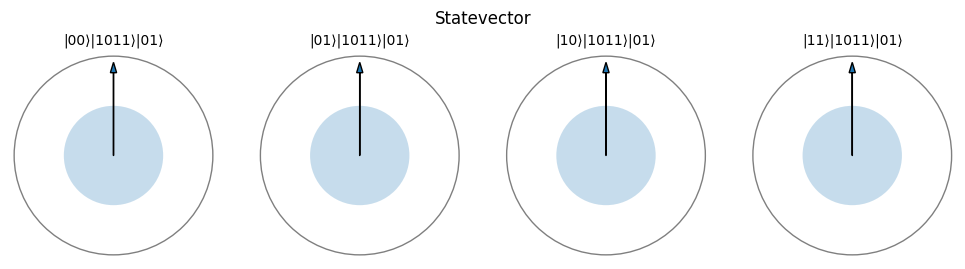

2
---------------------------------------


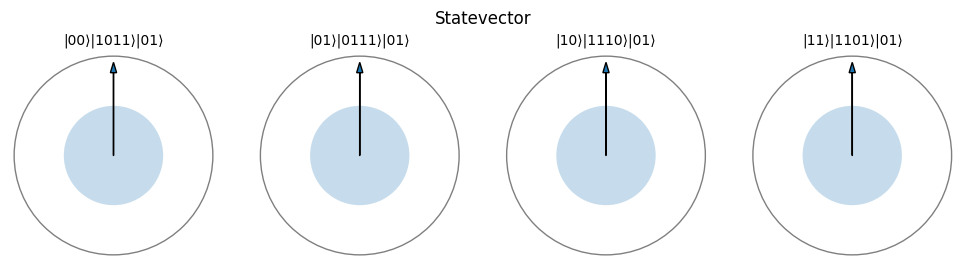

bitstring:  00111001
amp:  (0.4999999999999999+0j)
Shift k=1 (01): pattern_reg = '00'
bitstring:  01011110
amp:  (0.4999999999999999+0j)
Shift k=2 (10): pattern_reg = '10'
bitstring:  01101111
amp:  (0.4999999999999999+0j)
Shift k=3 (11): pattern_reg = '10'
bitstring:  11110100
amp:  (0.4999999999999999+0j)
Shift k=0 (00): pattern_reg = '11'


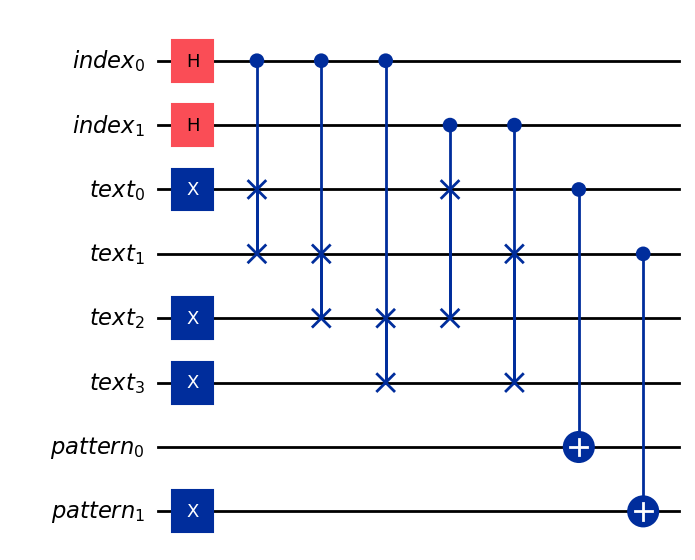

In [ ]:
# N is the length of Text pattern
# M is the length of pattern
import math
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector


text: str = "1011"
pattern: str = "01"

def prepare_input(text: str, pattern: str) -> tuple[QuantumCircuit, QuantumRegister, QuantumRegister, QuantumRegister]:
        # T = t0t1t2t3 = 1011
    # t_i <=> q_i,so t0 = q0
    # Paper/logical order: \(t_0,t_1,t_2,t_3\)
    # Qiskit printed ket order: \(q_3,q_2,q_1,q_0\)
    N: int = len(text)
    M: int = len(pattern)
    index_size: int = math.ceil(math.log2(N))

    print("N: ", N)
    print("M: ", M)
    print("i: ", index_size)


    # Index register has n = log2(N) qubits.

    # Text register: N qubits
    # Pattern register: M qubits
    # Index register: log2(N) qubits
    # Text and pattern are prepared as basis states.
    # Only the index register is put into uniform superposition.

    # The goal is to shift the text register using the index register we will create soon.


    index_reg = QuantumRegister(index_size, "index") # |k>
    text_reg = QuantumRegister(N, "text")            # |T>
    pattern_reg = QuantumRegister(M, "pattern")      # |P>

    qc = QuantumCircuit(index_reg, text_reg, pattern_reg)

    # Paper convention: text_reg[i] stores t_i.
    # Qiskit displays basis-state labels as |q_(N-1)...q_0|,
    # so printed bitstrings appear reversed relative to T = t0 t1 ... t_(N-1).
    def transform_text_reg(text):
        for i, bit in enumerate(text):
            if bit == "1":
                qc.x(text_reg[i])
            print("i: ", i)
            print("bit: ", bit)

    def transform_pattern_reg(pattern):
        for i, bit in enumerate(pattern):
            if bit == "1":
                qc.x(pattern_reg[i])
            print("i: ", i)
            print("bit: ", bit)

    print("------------------")
    transform_text_reg(text)
    print("------------------")

    transform_pattern_reg(pattern)

    # Put index register into uniform superposition
    qc.h(index_reg)

    return qc, index_reg, text_reg, pattern_reg

def verify_hadamard_uniformity(qc: QuantumCircuit, index_reg):
    state = Statevector.from_instruction(qc)

    index_qubits = [qc.find_bit(q).index for q in index_reg]

    print(state.probabilities_dict(qargs=index_qubits))

qc, index_reg, text_reg, pattern_reg = prepare_input(text, pattern)

print(qc.draw('text', fold=-1))
plot_state_vector(Statevector.from_instruction(qc).data)


print(len(index_reg))

# Left shifts the qubits of the text register by k positions.
def cyclic_shift_operator(qc, index_reg, text_reg):
    """Applies controlled cyclic left shift on a 4-qubit text register.

    - S1: shift by 1, controlled by index_reg[0] (k0, weight 2^0 = 1)
    - S2: shift by 2, controlled by index_reg[1] (k1, weight 2^1 = 2)
    """
    # ---S1 (shift by 1 if k0 == 1)---
    qc.cswap(index_reg[0], text_reg[0], text_reg[1])
    qc.cswap(index_reg[0], text_reg[1], text_reg[2])
    qc.cswap(index_reg[0], text_reg[2], text_reg[3])

    # ---S2 (shift by 2 if k1 == 1)---
    qc.cswap(index_reg[1], text_reg[0], text_reg[2])
    qc.cswap(index_reg[1], text_reg[1], text_reg[3])

# But we only want it to happen if k0 = 1
# Note for index_size = 2 such that k = 2k1 + k0 
# This means that if we have 1/2( |00> + |01> + |10> + |11> ) then |01> and |11> has k0 = 1
# So we replace with conditional 
print("---------------------------------------")
cyclic_shift_operator(qc, index_reg, text_reg)
plot_state_vector(Statevector.from_instruction(qc).data, "After applying cyclic shift")

#print(qc.draw('text', fold=-1))
qc.draw("mpl")

# Implement XOR
# After cycle shift all candidate bits are on the first M qubits of the text register.
# We apply the CNOT with each M first qubits between text_reg and pattern_reg
# Then we check if the outcome is 00 for any CNOT 
def apply_xor(qc, text_reg, pattern_reg):
    """Applies the XOR function via controlled NOTs on the pattern register with the text register.
    """
    for i in range(len(pattern_reg)):
        qc.cx(text_reg[i], pattern_reg[i])

apply_xor(qc, text_reg, pattern_reg)
#print(qc.draw('text', fold=-1))
debug_xor(qc)

# Grover Oracle
# We need to identify exact matches. How do we do that?
# We can simply look at the pattern registers that are all zero.
# We must also ensure that no invalid positions are considered correct.
# The grover oracle is an operator that acts on the pattern register.
# Its operation is only to flip the sign of 
qc.draw("mpl")


